# Module 7 — Brownian Motion and Geometric Brownian Motion

**Probability Simulation Laboratory** · Module 7 of 8

## Learning objectives
1. see Brownian motion as the scaling limit of a random walk (**Donsker's theorem**);
2. state the defining properties of Brownian motion and verify them by simulation;
3. explain why Brownian paths are continuous but nowhere differentiable: **quadratic variation** $[W]_T=T$ versus infinite **total variation**;
4. simulate **geometric Brownian motion** (GBM), derive its moments and the **Itô correction** $-\tfrac12\sigma^2$, and measure the convergence order of the Euler scheme;
5. verify the **reflection principle** for the running maximum, including the bias introduced by discrete monitoring.

## Research objective
How does randomness generate continuous-time stochastic behaviour, and what does that imply for models of asset prices?

In [1]:
import sys, pathlib

# Locate the repository root so the notebook runs from anywhere inside the repo.
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "src" / "plab").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Run this notebook from inside the probability-simulation-laboratory repository.")
    ROOT = ROOT.parent
for p in [ROOT / "src", *sorted(ROOT.glob("0*/src"))]:
    sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from plab import make_rng, save_fig, set_style, wilson_interval, mean_ci

set_style()
RESULTS = ROOT / "07_brownian_motion" / "results"
rng = make_rng(20261031)          # one seeded Generator -> every number below is reproducible
pd.set_option("display.precision", 5)
pd.set_option("display.width", 140)

In [2]:
import brownian as bm          # 07_brownian_motion/src/brownian.py (re-exports plab.processes)

## 1. Mathematical background

**Definition (standard Brownian motion).** A process $W=\{W_t\}_{t\ge0}$ with
1. $W_0=0$;
2. *independent increments*: $W_t-W_s$ is independent of $\{W_u:u\le s\}$ for $s<t$;
3. *stationary Gaussian increments*: $W_t-W_s\sim\mathcal N(0,t-s)$;
4. *continuous paths*.

Consequences: $\operatorname{Var}W_t=t$, $\operatorname{Cov}(W_s,W_t)=\min(s,t)$, and **self-similarity** $W_{ct}\overset d=\sqrt c\,W_t$. $W$ and $W_t^2-t$ are martingales.

**Donsker's theorem (invariance principle).** For a $\pm1$ walk $S_k$, the rescaled interpolated process $W^{(n)}(t)=S_{\lfloor nt\rfloor}/\sqrt n$ converges in distribution (as a process) to $W$. At a fixed time this is the CLT; Donsker is the *functional* version, so it also applies to path functionals such as the maximum.

**Quadratic variation.** For a partition $\Pi_n$ of $[0,T]$ into $n$ equal steps,
$$\sum_{k}(\Delta W_k)^2\;\longrightarrow\;T\quad(n\to\infty),$$
with mean exactly $T$ and variance $\sum_k\operatorname{Var}(\Delta W_k^2)=n\cdot2(T/n)^2=2T^2/n\to0$. In contrast the **total variation** satisfies $\mathbb E\sum_k|\Delta W_k|=n\sqrt{2T/(n\pi)}=\sqrt{2nT/\pi}\to\infty$. So $W$ has paths of infinite length yet finite quadratic variation; this is why ordinary calculus fails and **Itô's formula** has the extra second-order term.

**Geometric Brownian motion.** The SDE $dS_t=\mu S_tdt+\sigma S_tdW_t$ has the solution (Itô's formula applied to $\log S$)
$$S_t=S_0\exp\!\Big(\big(\mu-\tfrac12\sigma^2\big)t+\sigma W_t\Big).$$
Hence $\log S_t$ is normal; $S_t$ is lognormal with $\mathbb ES_t=S_0e^{\mu t}$, $\operatorname{Var}S_t=S_0^2e^{2\mu t}(e^{\sigma^2t}-1)$, median $S_0e^{(\mu-\sigma^2/2)t}$. The *Itô correction* $-\tfrac12\sigma^2$ appears because $\mathbb E e^{\sigma W_t}=e^{\sigma^2t/2}$ (Jensen). The long-run growth rate of a typical path is $\mu-\tfrac12\sigma^2$ ($\tfrac1t\log S_t\to\mu-\tfrac12\sigma^2$ a.s.), which can be negative even when $\mathbb ES_t$ grows.

**Euler–Maruyama.** $S_{k+1}=S_k(1+\mu\Delta t+\sigma\Delta W_k)$. *Strong error* $\mathbb E|S_T^{\text{Euler}}-S_T|=O(\Delta t^{1/2})$; *weak error* $|\mathbb E f(S_T^{\text{Euler}})-\mathbb Ef(S_T)|=O(\Delta t)$. For GBM, $\mathbb ES_T^{\text{Euler}}=S_0(1+\mu T/n)^n$ exactly.

**Reflection principle.** For $a>0$: $P(\max_{s\le T}W_s\ge a)=2P(W_T\ge a)=2\big(1-\Phi(a/\sqrt T)\big)$. A path that hits $a$ is equally likely to end above or below $a$ (reflect it after the hitting time). If the maximum is observed only on a grid of spacing $\Delta t$, the result is biased low: the Broadie–Glasserman–Kou correction says a discretely monitored barrier $a$ behaves like a continuous one shifted to $a+\beta\sqrt{\Delta t}$, $\beta=-\zeta(1/2)/\sqrt{2\pi}\approx0.5826$.

## Experiment 7.1

**A. Experiment title.** Donsker's invariance principle: the scaled random walk $S_{\lfloor nt\rfloor}/\sqrt n$ converges to Brownian motion.

**B. Research question.** How quickly does the rescaled random walk become Gaussian as the number of steps $n$ grows?

**C. Mathematical foundation.**

$W^{(n)}(1)=S_n/\sqrt n=\dfrac{2K-n}{\sqrt n}$, $K\sim\text{Bin}(n,\tfrac12)$. By the CLT $W^{(n)}(1)\Rightarrow\mathcal N(0,1)$. Berry–Esseen gives a Kolmogorov distance of order $1/\sqrt n$ (here dominated by the lattice jump: the cdf jumps by $\approx\sqrt{2/(\pi n)}$ at each atom, so $D_n\gtrsim\tfrac12\sqrt{2/(\pi n)}\approx0.4/\sqrt n$).

**D. Theoretical prediction.**

$D_n=\sup_x|F_n(x)-\Phi(x)|\approx0.4/\sqrt n$, i.e. a log–log slope of $-\tfrac12$ against $n$ (in fact $D_n\sqrt n\to1/\sqrt{2\pi}=0.3989$); this is the exact (not simulated) distance, because the binomial cdf is available in closed form. Plotted paths of $W^{(n)}$ look increasingly like a continuous Brownian path as $n$ grows.

**E. Experimental design.**

(i) Exact Kolmogorov distance between the law of $S_n/\sqrt n$ and $\Phi$ for $n=1,\dots,10^6$ (computed from the binomial cdf). (ii) One path of $W^{(n)}$ for $n=10,100,10^4$. (iii) Simulated terminal values ($200{,}000$ replicates) for $n=100$ to compare the empirical distribution with $\mathcal N(0,1)$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

log-log slope of D_n against n: -0.493   (theory -0.5)
simulated n=100: mean -0.0001, variance 1.0035


,exact KS distance D_n,D_n * sqrt(n)
n,,
1,0.34134,0.34134
4,0.18750,0.37500
16,0.09819,0.39276
64,0.04967,0.39739
256,0.02491,0.39855
1024,0.01246,0.39884
4096,0.00623,0.39892
16384,0.00312,0.39894
65536,0.00156,0.39894


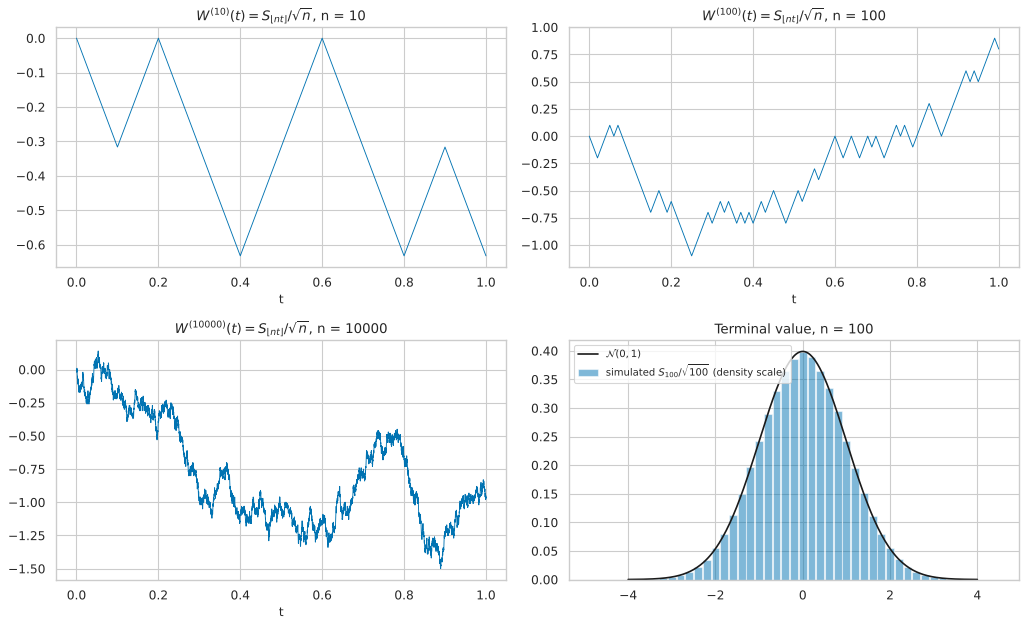

In [3]:
# F. Implementation ------------------------------------------------------------------
# bm.scaled_walk_path(n, rng)      -> t_k = k/n, W^(n)(t_k) = S_k / sqrt(n)
# bm.scaled_walk_terminal(n, reps) -> S_n / sqrt(n)  via S_n = 2*Binomial(n, 1/2) - n
rng = make_rng(20261031 + 71)

def exact_kolmogorov_distance(n):
    # law of S_n/sqrt(n): atoms x_k = (2k - n)/sqrt(n) with masses Binom(n, 1/2); sup |F - Phi| is attained at atoms
    k = np.arange(n + 1)
    x = (2 * k - n) / np.sqrt(n)
    cdf_after = stats.binom.cdf(k, n, 0.5)
    cdf_before = np.r_[0.0, cdf_after[:-1]]
    phi = stats.norm.cdf(x)
    return max(np.abs(cdf_after - phi).max(), np.abs(cdf_before - phi).max())

ns = np.array([1, 4, 16, 64, 256, 1024, 4096, 16384, 65536, 262144, 1048576])
D = np.array([exact_kolmogorov_distance(int(n)) for n in ns])
slope = np.polyfit(np.log(ns), np.log(D), 1)[0]
dtab = pd.DataFrame({"n": ns, "exact KS distance D_n": D, "D_n * sqrt(n)": D * np.sqrt(ns)}).set_index("n")
dtab.to_csv(RESULTS / "exp7_1_donsker_distance.csv")
display(dtab)
print(f"log-log slope of D_n against n: {slope:.3f}   (theory -0.5)")

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for a, n in zip(ax.ravel()[:3], (10, 100, 10_000)):
    t, w = bm.scaled_walk_path(n, rng)
    a.plot(t, w, lw=0.8); a.set(title=f"$W^{{({n})}}(t) = S_{{\\lfloor nt\\rfloor}}/\\sqrt{{n}}$, n = {n}", xlabel="t")
z = bm.scaled_walk_terminal(100, 200_000, rng)
vals, counts = np.unique(z, return_counts=True)
a = ax.ravel()[3]
a.bar(vals, counts / counts.sum() / 0.2, width=0.18, alpha=0.5, label="simulated $S_{100}/\\sqrt{100}$ (density scale)")
g = np.linspace(-4, 4, 300); a.plot(g, stats.norm.pdf(g), "k", label="$\\mathcal{N}(0,1)$"); a.legend(); a.set(title="Terminal value, n = 100")
fig.tight_layout(); save_fig(fig, RESULTS, "exp7_1_donsker.png")
print("simulated n=100: mean %.4f, variance %.4f" % (z.mean(), z.var(ddof=1)))

**H. Theoretical versus empirical comparison.**

The exact Kolmogorov distance falls like $n^{-1/2}$ (slope printed above) with $D_n\sqrt n\to0.3989=1/\sqrt{2\pi}$ — the lattice constant (half the atom mass $\sqrt{2/(\pi n)}$ divided by $1/\sqrt n$); the simulated terminal values at $n=100$ have mean $\approx0$ and variance $\approx1$, as the CLT predicts, and the sample paths turn from visibly jagged staircases into something that looks like a continuous curve.

**I. Interpretation.**

Brownian motion is not an arbitrary choice: *any* finite-variance, independent-increment noise accumulated over many small time steps produces it. This universality is the justification for using BM as the building block for diffusion models of prices. Note that the convergence is of the *process*; the paths of $W^{(n)}$ are piecewise linear, but their limit is nowhere differentiable.

**J. Limitations.**

The ±1 steps are the simplest case; distributions with finite variance work equally, but heavy-tailed increments (infinite variance) converge to a *stable* process instead (Module 4). The Kolmogorov distance measures only the one-dimensional marginal at $t=1$.

**K. Research conclusion.**

The scaled random walk converges to Brownian motion, with rate $n^{-1/2}$ in Kolmogorov distance at a fixed time.

**L. Further investigation.**

Replace $\pm1$ steps by centred exponential or uniform steps and check that the limit is the same; compare the distribution of the running maximum of $W^{(n)}$ with the reflection principle (Experiment 7.5).

## Experiment 7.2

**A. Experiment title.** Defining properties of Brownian motion: $\operatorname{Var}W_t=t$, $\operatorname{Cov}(W_s,W_t)=\min(s,t)$, Gaussian independent increments, self-similarity.

**B. Research question.** Do simulated Brownian paths satisfy the defining properties of the process?

**C. Mathematical foundation.**

With $W_{t_k}=\sum_{j\le k}\sqrt{\Delta t}\,Z_j$, $Z_j\overset{iid}\sim\mathcal N(0,1)$, the grid values have *exactly* the finite-dimensional law of BM (no discretisation error at grid points). Hence $\operatorname{Var}W_t=t$, $\operatorname{Cov}(W_s,W_t)=\min(s,t)$, increments over disjoint intervals are independent $\mathcal N(0,\text{length})$, and $W_{ct}/\sqrt c\overset d=W_t$.

**D. Theoretical prediction.**

Sample variances $\approx0.25,0.5,1.0$ at $t=0.25,0.5,1$; sample covariance matrix of $(W_{0.25},W_{0.5},W_{1})\approx\begin{pmatrix}.25&.25&.25\\.25&.5&.5\\.25&.5&1\end{pmatrix}$; correlation between increments on $(0,.5]$ and $(.5,1]$ $\approx0$; Kolmogorov–Smirnov p-values for increment normality not systematically small; variance of $W_t$ at $t=1$ equals that of $\sqrt 4\,W_{1/4}$.

**E. Experimental design.**

$20{,}000$ paths, $500$ steps on $[0,1]$.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

sample covariance of (W_.25, W_.5, W_1):
 [[0.248 0.251 0.25 ]
 [0.251 0.503 0.504]
 [0.25  0.504 1.006]]
theory min(s,t):
 [[0.25 0.25 0.25]
 [0.25 0.5  0.5 ]
 [0.25 0.5  1.  ]]
max abs error: 0.0062
increments on (0,.5] and (.5,1]: variances 0.5028, 0.5006 (theory 0.5)
KS vs N(0,.5): D = 0.0053 (p=0.64) and 0.0039 (p=0.92)
corr(increment 1, increment 2) = +0.0028  (theory 0; SE ~ 0.0071)
corr(inc1^2, inc2^2) = +0.0073  (theory 0)
Var(W_1) = 1.0062,  Var(2 W_.25) = 0.9928  (both theory 1)
two-sample KS: W_1 vs 2 W_.25 : D = 0.0071


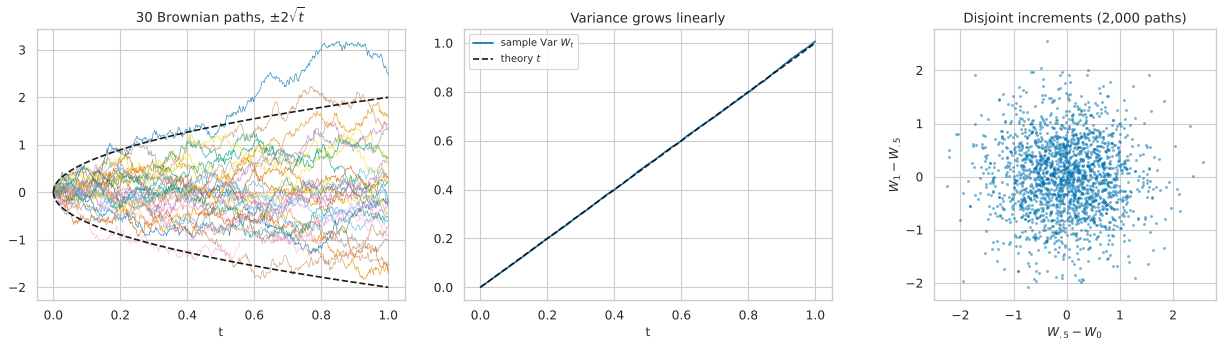

PosixPath('/home/claude/probability-simulation-laboratory/07_brownian_motion/results/exp7_2_bm_properties.png')

In [4]:
# F. Implementation ------------------------------------------------------------------
rng = make_rng(20261031 + 72)
n_steps, n_paths, T = 500, 20_000, 1.0
t, W = bm.brownian_paths(n_steps, T, n_paths, rng)       # W[:, k] = W(t_k), exact in law at grid points
idx = {0.25: n_steps // 4, 0.5: n_steps // 2, 1.0: n_steps}

# G/H. Variance and covariance ---------------------------------------------------------------------
sub = np.column_stack([W[:, idx[s]] for s in (0.25, 0.5, 1.0)])
cov_hat = np.cov(sub.T)
cov_th = np.array([[min(s, u) for u in (0.25, 0.5, 1.0)] for s in (0.25, 0.5, 1.0)])
print("sample covariance of (W_.25, W_.5, W_1):\n", cov_hat.round(3))
print("theory min(s,t):\n", cov_th)
print("max abs error:", np.abs(cov_hat - cov_th).max().round(4))

# Increments: normal and independent ------------------------------------------------------------------
inc1 = W[:, idx[0.5]] - W[:, 0]
inc2 = W[:, idx[1.0]] - W[:, idx[0.5]]
ks1 = stats.kstest(inc1 / np.sqrt(0.5), "norm"); ks2 = stats.kstest(inc2 / np.sqrt(0.5), "norm")
print(f"increments on (0,.5] and (.5,1]: variances {inc1.var(ddof=1):.4f}, {inc2.var(ddof=1):.4f} (theory 0.5)")
print(f"KS vs N(0,.5): D = {ks1.statistic:.4f} (p={ks1.pvalue:.2f}) and {ks2.statistic:.4f} (p={ks2.pvalue:.2f})")
print(f"corr(increment 1, increment 2) = {np.corrcoef(inc1, inc2)[0, 1]:+.4f}  (theory 0; SE ~ {1 / np.sqrt(n_paths):.4f})")
# dependence beyond correlation: squared increments should be uncorrelated too
print(f"corr(inc1^2, inc2^2) = {np.corrcoef(inc1**2, inc2**2)[0, 1]:+.4f}  (theory 0)")

# Self-similarity: W_1 vs 2 * W_{1/4} --------------------------------------------------------------------
w_quarter, w_one = W[:, idx[0.25]], W[:, idx[1.0]]
print(f"Var(W_1) = {w_one.var(ddof=1):.4f},  Var(2 W_.25) = {(2 * w_quarter).var(ddof=1):.4f}  (both theory 1)")
print(f"two-sample KS: W_1 vs 2 W_.25 : D = {stats.ks_2samp(w_one, 2 * w_quarter).statistic:.4f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for p in W[:30]:
    ax[0].plot(t, p, lw=0.6, alpha=0.8)
ax[0].plot(t, 2 * np.sqrt(t), "k--"); ax[0].plot(t, -2 * np.sqrt(t), "k--"); ax[0].set(title="30 Brownian paths, $\\pm 2\\sqrt{t}$", xlabel="t")
var_t = W.var(axis=0, ddof=1); ax[1].plot(t, var_t, label="sample Var $W_t$"); ax[1].plot(t, t, "k--", label="theory $t$"); ax[1].legend(); ax[1].set(title="Variance grows linearly", xlabel="t")
ax[2].scatter(inc1[:2000], inc2[:2000], s=3, alpha=0.4); ax[2].set(xlabel="$W_{.5}-W_0$", ylabel="$W_1-W_{.5}$", title="Disjoint increments (2,000 paths)", aspect="equal")
fig.tight_layout(); save_fig(fig, RESULTS, "exp7_2_bm_properties.png")

**H. Theoretical versus empirical comparison.**

All the quantities listed in D are reproduced within sampling noise (see printed values: largest covariance error $0.006$ with $20{,}000$ paths, increment correlation $+0.003$ (SE $0.007$), KS p-values $0.64$ and $0.92$, KS tests that do not reject, equal variances for $W_1$ and $2W_{1/4}$).

**I. Interpretation.**

Independence of increments is what makes BM a martingale with *no memory*: the past path says nothing about the future increment. Self-similarity says that the picture looks statistically the same under zooming (with the $\sqrt{\cdot}$ rescaling) — which is why the path is a fractal-like object with no smooth scale.

**J. Limitations.**

We only check the process at $501$ grid points. Continuity and the behaviour *between* grid points are assumptions of the construction, not things the simulation checks. A zero sample correlation does not by itself prove independence, which is why the squared-increment correlation was also inspected.

**K. Research conclusion.**

Grid values generated from cumulated Gaussian increments have exactly the Brownian covariance structure, independent Gaussian increments and the square-root scaling.

**L. Further investigation.**

Simulate a *Brownian bridge* (condition $W_1=0$) and use it to verify $\operatorname{Cov}=\min(s,t)-st$; refine a coarse path with Lévy's midpoint construction.

## Experiment 7.3

**A. Experiment title.** Quadratic versus total variation of Brownian paths on a sequence of nested dyadic grids.

**B. Research question.** Why can't we treat $dW$ like an ordinary differential? How do the sums $\sum(\Delta W)^2$ and $\sum|\Delta W|$ behave as the mesh goes to zero?

**C. Mathematical foundation.**

On a grid with $n$ equal steps on $[0,T]$ ($T=1$): $\mathbb E\sum(\Delta W)^2=T$, $\operatorname{Var}\sum(\Delta W)^2=2T^2/n$; $\mathbb E\sum|\Delta W|=\sqrt{2nT/\pi}$.

**D. Theoretical prediction.**

Mean quadratic variation $=1$ for every $n$ with variance $2/n$ (log–log slope $-1$); the mean total variation grows like $\sqrt n$ (log–log slope $+\tfrac12$, value $\sqrt{2n/\pi}$). Along nested grids the quadratic variation of *each* path converges to 1.

**E. Experimental design.**

Simulate $2{,}000$ paths with $2^{14}=16{,}384$ steps, then coarsen the *same* increments to $n=2^2,\dots,2^{14}$ (nested dyadic grids, so each path is observed at progressively finer resolution).

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

log-log slope of Var(QV) vs n : -0.996  (theory -1)
log-log slope of E[TV]  vs n : 0.500  (theory +0.5)


,QV_mean,QV_var,QV_var_theory,TV_mean,TV_theory,max_abs_QV_error
n,,,,,,
4,0.99969,0.51293,0.50000,1.59387,1.59577,4.14855
8,0.99571,0.24247,0.25000,2.25267,2.25676,2.45238
16,0.99440,0.12539,0.12500,3.18200,3.19154,1.69621
32,0.99462,0.06296,0.06250,4.50089,4.51352,1.09266
64,0.99563,0.02946,0.03125,6.36562,6.38308,0.88087
128,0.99801,0.01540,0.01562,9.01560,9.02703,0.55848
256,0.99779,0.00779,0.00781,12.74934,12.76615,0.45618
512,0.99994,0.00376,0.00391,18.05664,18.05407,0.22180
1024,0.99986,0.00192,0.00195,25.52478,25.53231,0.15905


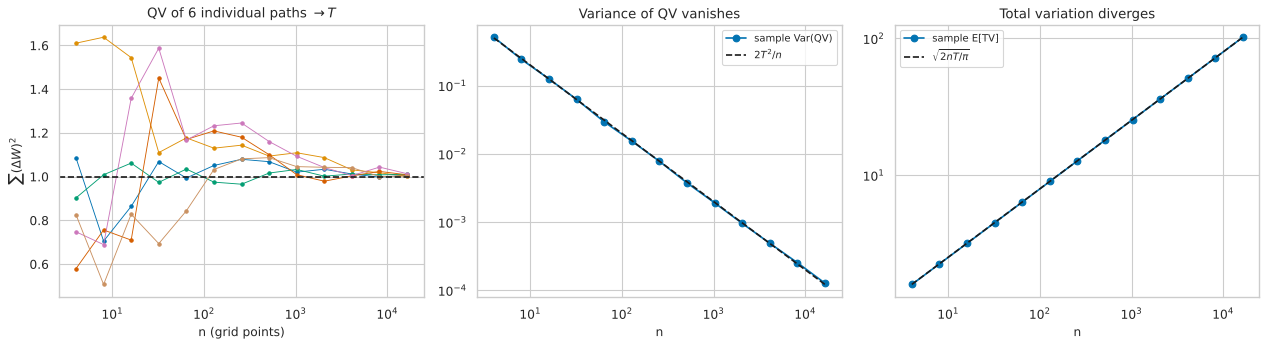

PosixPath('/home/claude/probability-simulation-laboratory/07_brownian_motion/results/exp7_3_variation.png')

In [5]:
# F. Implementation ------------------------------------------------------------------
# bm.coarsen_increments(dW_fine, n) -> increments on a coarser grid of the same paths
# bm.quadratic_variation(dW)        -> sum (Delta W)^2 per path
# bm.total_variation(dW)            -> sum |Delta W| per path
rng = make_rng(20261031 + 73)
T, n_fine, n_paths = 1.0, 2 ** 14, 2000
dW_fine = bm.brownian_increments(n_fine, T, n_paths, rng)
levels = [2 ** k for k in range(2, 15)]

rows = []
for n in levels:
    dW = bm.coarsen_increments(dW_fine, n)
    qv, tv = bm.quadratic_variation(dW), bm.total_variation(dW)
    rows.append(dict(n=n, QV_mean=qv.mean(), QV_var=qv.var(ddof=1), QV_var_theory=2 * T ** 2 / n,
                     TV_mean=tv.mean(), TV_theory=np.sqrt(2 * n * T / np.pi), max_abs_QV_error=np.abs(qv - T).max()))
tab = pd.DataFrame(rows).set_index("n")
tab.to_csv(RESULTS / "exp7_3_variation.csv")
display(tab)

n_arr = np.array(levels, dtype=float)
slope_qv = np.polyfit(np.log(n_arr), np.log(tab.QV_var), 1)[0]
slope_tv = np.polyfit(np.log(n_arr), np.log(tab.TV_mean), 1)[0]
print(f"log-log slope of Var(QV) vs n : {slope_qv:.3f}  (theory -1)")
print(f"log-log slope of E[TV]  vs n : {slope_tv:.3f}  (theory +0.5)")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for i in range(6):
    ax[0].semilogx(levels, [bm.quadratic_variation(bm.coarsen_increments(dW_fine[i:i + 1], n))[0] for n in levels], "o-", ms=3, lw=0.8)
ax[0].axhline(T, color="k", ls="--"); ax[0].set(xlabel="n (grid points)", ylabel="$\\sum (\\Delta W)^2$", title="QV of 6 individual paths $\\to T$")
ax[1].loglog(levels, tab.QV_var, "o-", label="sample Var(QV)"); ax[1].loglog(levels, tab.QV_var_theory, "k--", label="$2T^2/n$"); ax[1].legend(); ax[1].set(xlabel="n", title="Variance of QV vanishes")
ax[2].loglog(levels, tab.TV_mean, "o-", label="sample E[TV]"); ax[2].loglog(levels, tab.TV_theory, "k--", label="$\\sqrt{2nT/\\pi}$"); ax[2].legend(); ax[2].set(xlabel="n", title="Total variation diverges")
fig.tight_layout(); save_fig(fig, RESULTS, "exp7_3_variation.png")

**H. Theoretical versus empirical comparison.**

The mean of the quadratic variation is $\approx1$ at every resolution with variance tracking $2/n$ (slope printed above close to $-1$); the mean total variation tracks $\sqrt{2n/\pi}$ (slope close to $+\tfrac12$). Individual paths settle onto the line $[W]_T=T$ as the grid is refined.

**I. Interpretation.**

A path of finite total variation would have vanishing quadratic variation ($\sum(\Delta f)^2\le\max|\Delta f|\sum|\Delta f|\to0$ for continuous $f$). Brownian motion has non-zero quadratic variation, therefore *infinite* total variation and no derivative anywhere. In stochastic calculus, $(dW)^2=dt$ replaces the vanishing $(dx)^2$ of ordinary calculus; it is exactly the term that creates the $-\tfrac12\sigma^2$ in GBM and the second-order term in Itô's formula, and it underlies realised-variance estimators in finance.

**J. Limitations.**

We observe a *discrete* sample, so "quadratic variation" is the limit of a sequence of finite sums, and the convergence along a *nested* sequence is what we check. In real markets, microstructure noise makes realised variance blow up at very high frequency, so the idealised $n\to\infty$ limit is not attainable for observed prices.

**K. Research conclusion.**

Brownian paths have quadratic variation $T$ and infinite total variation; both rates are reproduced by simulation.

**L. Further investigation.**

Estimate the quadratic variation of a GBM path and recover $\sigma^2T$; add i.i.d. noise to the observed prices and show how realised variance becomes biased as sampling frequency increases.

## Experiment 7.4

**A. Experiment title.** Geometric Brownian motion: exact lognormal moments, the Itô correction, and convergence orders of the Euler–Maruyama scheme.

**B. Research question.** What does the Itô correction $-\tfrac12\sigma^2$ mean for typical paths versus the average, and how accurately does the Euler scheme reproduce GBM?

**C. Mathematical foundation.**

Parameters $S_0=100$, $\mu=0.08$, $\sigma=0.3$, $T=1$. Theory: $\mathbb ES_T=100e^{0.08}=108.33$; median $100e^{0.08-0.045}=103.56$; $\operatorname{Var}S_T=S_0^2e^{2\mu T}(e^{\sigma^2T}-1)$; $\log S_T\sim\mathcal N(\log S_0+(\mu-\sigma^2/2)T,\sigma^2T)$.
*Itô correction in the long run*: with $\mu=0.04$, $\sigma=0.3$ we have $\mu-\sigma^2/2=-0.005<0$, so for horizon $T=400$ $P(S_T<S_0)=\Phi\!\big(-(\mu-\sigma^2/2)\sqrt T/\sigma\big)=\Phi(0.333)\approx0.63$ even though $\mathbb ES_T=S_0e^{\mu T}$ grows enormously.
*Euler*: strong error $\propto\Delta t^{1/2}$, weak error of the mean $\propto\Delta t$ with $\mathbb ES^{\text{Euler}}_T=S_0(1+\mu T/n)^n$.

**D. Theoretical prediction.**

(i) Sample mean/variance/median of $S_T$ match the formulas; $\log S_T$ is normal (KS). (ii) For $T=400$ about $63\%$ of paths end below $S_0$. (iii) The log–log slope of the Euler strong error against $n$ is about $-\tfrac12$ and the weak error of the mean has slope $-1$.

**E. Experimental design.**

(i) $2{,}000{,}000$ terminal values from `gbm_terminal` with standard normal draws. (ii) $200{,}000$ terminal values at $T=400$. (iii) Strong error: `euler_strong_error` with $n=4,8,\dots,1024$ steps, $20{,}000$ paths sharing one Brownian path per replicate. (iv) Weak error exactly from $S_0(1+\mu T/n)^n-S_0e^{\mu T}$ plus its simulated counterpart.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

95% CI for E[S_T]: [108.304, 108.396] contains 108.329: True
KS distance of standardised log S_T to N(0,1): 0.00056  (p = 0.56)

mu = 0.04, sigma = 0.3: growth rate of a typical path mu - sigma^2/2 = -0.0050
P(S_T < S_0) at T = 400: theory 0.6306, simulated 0.6310  (Wilson [0.6289, 0.6332])
E[S_T]/S_0 = e^(mu T) = 8.886e+06   but median S_T/S_0 = 0.135
(1/T) log(S_T/S_0): mean -0.00502 (theory -0.00500)
log-log slope, strong: -0.492 (theory -0.5);   weak: -0.998 (theory -1)


,theory,simulated
E[S_T],108.32871,108.35026
Var[S_T],1105.14546,1104.35468
median S_T,103.56197,103.62507
E[log S_T],4.64017,4.64041
sd(log S_T),0.30000,0.29989


,strong error E|Euler - exact|,weak error of the mean (exact formula)
n,,
4,2.58951,0.08549
8,1.89843,0.04304
16,1.34909,0.02159
32,0.96744,0.01081
64,0.68895,0.00541
128,0.48845,0.00271
256,0.34319,0.00135
512,0.24277,0.00068
1024,0.17141,0.00034


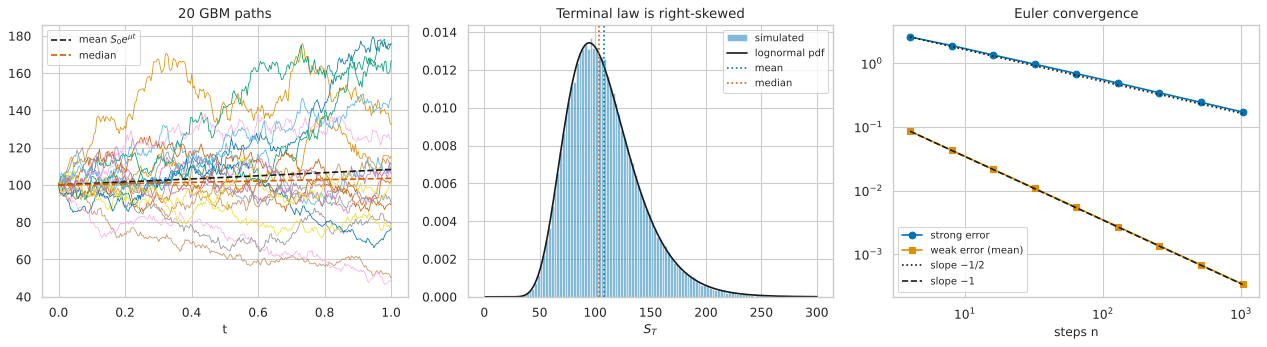

PosixPath('/home/claude/probability-simulation-laboratory/07_brownian_motion/results/exp7_4_gbm.png')

In [6]:
# F. Implementation ------------------------------------------------------------------
rng = make_rng(20261031 + 74)
S0, mu, sigma, T = 100.0, 0.08, 0.3, 1.0
th = bm.gbm_theoretical_moments(S0, mu, sigma, T)

# (i) exact terminal law ------------------------------------------------------------------------------------
n_sim = 2_000_000
ST = bm.gbm_terminal(S0, mu, sigma, T, rng.standard_normal(n_sim))
m, lo, hi = mean_ci(ST)
lg = np.log(ST)
ks = stats.kstest((lg - lg.mean()) / lg.std(ddof=1), "norm")
tab = pd.DataFrame({"theory": [th["mean"], th["var"], th["median"], np.log(S0) + (mu - sigma ** 2 / 2) * T, sigma * np.sqrt(T)],
                    "simulated": [ST.mean(), ST.var(ddof=1), np.median(ST), lg.mean(), lg.std(ddof=1)]},
                   index=["E[S_T]", "Var[S_T]", "median S_T", "E[log S_T]", "sd(log S_T)"])
display(tab)
print(f"95% CI for E[S_T]: [{lo:.3f}, {hi:.3f}] contains {th['mean']:.3f}: {lo <= th['mean'] <= hi}")
print(f"KS distance of standardised log S_T to N(0,1): {ks.statistic:.5f}  (p = {ks.pvalue:.2f})")
tab.to_csv(RESULTS / "exp7_4_gbm_moments.csv")

# (ii) Ito correction in the long run ------------------------------------------------------------------------------
mu2, T2 = 0.04, 400.0
g = mu2 - sigma ** 2 / 2
ST2 = bm.gbm_terminal(S0, mu2, sigma, T2, rng.standard_normal(200_000))
p_loss_th = stats.norm.cdf(-g * np.sqrt(T2) / sigma)
p_loss_sim = np.mean(ST2 < S0)
lo2, hi2 = wilson_interval(int((ST2 < S0).sum()), ST2.size)
print(f"\nmu = {mu2}, sigma = {sigma}: growth rate of a typical path mu - sigma^2/2 = {g:+.4f}")
print(f"P(S_T < S_0) at T = {T2:.0f}: theory {p_loss_th:.4f}, simulated {p_loss_sim:.4f}  (Wilson [{lo2:.4f}, {hi2:.4f}])")
print(f"E[S_T]/S_0 = e^(mu T) = {np.exp(mu2 * T2):.3e}   but median S_T/S_0 = {np.median(ST2) / S0:.3f}")
print(f"(1/T) log(S_T/S_0): mean {np.mean(np.log(ST2 / S0)) / T2:+.5f} (theory {g:+.5f})")

# (iii) Euler strong and weak error ---------------------------------------------------------------------------------
levels = [4, 8, 16, 32, 64, 128, 256, 512, 1024]
strong = bm.euler_strong_error(S0, mu, sigma, T, levels, 20_000, rng)
weak = np.array([abs(S0 * (1 + mu * T / n) ** n - th["mean"]) for n in levels])
sl_s = np.polyfit(np.log(levels), np.log(strong), 1)[0]
sl_w = np.polyfit(np.log(levels), np.log(weak), 1)[0]
etab = pd.DataFrame({"n": levels, "strong error E|Euler - exact|": strong, "weak error of the mean (exact formula)": weak}).set_index("n")
etab.to_csv(RESULTS / "exp7_4_euler_errors.csv")
display(etab)
print(f"log-log slope, strong: {sl_s:.3f} (theory -0.5);   weak: {sl_w:.3f} (theory -1)")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
tt, S = bm.gbm_exact_paths(S0, mu, sigma, T, 252, 20, rng)
for p in S: ax[0].plot(tt, p, lw=0.7)
ax[0].plot(tt, S0 * np.exp(mu * tt), "k--", label="mean $S_0e^{\\mu t}$"); ax[0].plot(tt, S0 * np.exp((mu - sigma ** 2 / 2) * tt), "r--", label="median"); ax[0].legend(); ax[0].set(title="20 GBM paths", xlabel="t")
ax[1].hist(ST[:200_000], bins=120, density=True, alpha=0.5, range=(0, 300), label="simulated")
xs = np.linspace(1, 300, 400); ax[1].plot(xs, stats.lognorm(s=sigma * np.sqrt(T), scale=np.exp(np.log(S0) + (mu - sigma ** 2 / 2) * T)).pdf(xs), "k", label="lognormal pdf")
ax[1].axvline(th["mean"], color="b", ls=":", label="mean"); ax[1].axvline(th["median"], color="r", ls=":", label="median"); ax[1].legend(); ax[1].set(title="Terminal law is right-skewed", xlabel="$S_T$")
ax[2].loglog(levels, strong, "o-", label="strong error"); ax[2].loglog(levels, weak, "s-", label="weak error (mean)")
ax[2].loglog(levels, strong[0] * (np.array(levels) / levels[0]) ** -0.5, "k:", label="slope $-1/2$"); ax[2].loglog(levels, weak[0] * (np.array(levels) / levels[0]) ** -1.0, "k--", label="slope $-1$")
ax[2].legend(); ax[2].set(xlabel="steps n", title="Euler convergence")
fig.tight_layout(); save_fig(fig, RESULTS, "exp7_4_gbm.png")

**H. Theoretical versus empirical comparison.**

See the printed tables: moments and the median of $S_T$ agree with the lognormal formulas (the $95\%$ CI for the mean contains $108.33$), and $\log S_T$ is indistinguishable from normal. In the long-horizon experiment the simulated loss probability matches $\Phi(0.333)\approx0.63$ even though $\mathbb ES_T$ grows by a factor of $e^{16}$. The Euler strong error has slope $\approx-0.5$ and the weak error of the mean exactly slope $-1$ (it is $S_0\big((1+\mu T/n)^n-e^{\mu T}\big)\approx-\tfrac12S_0\mu^2Te^{\mu T}/n$).

**I. Interpretation.**

**Mean versus typical path.** The mean of a GBM is dominated by a few huge outcomes, so it is a poor description of what a *typical* investor experiences; the median and the long-run growth rate $\mu-\tfrac12\sigma^2$ (the *volatility drag*) tell the story of one realised path. This is the origin of "volatility is a tax on compound returns" and of the Kelly-growth viewpoint. **Numerics.** Pathwise accuracy of Euler is only $\Delta t^{1/2}$, but expectations converge at the faster $\Delta t$ rate, so Euler is acceptable for pricing (weak quantity) yet poor for reproducing individual paths; for GBM we avoid the problem altogether by using the exact solution.

**J. Limitations.**

GBM has constant volatility and continuous paths, and cannot reproduce volatility smiles, jumps or fat tails (see Module 8). The $T=400$ years horizon is a mathematical illustration, not a realistic investment horizon. Euler error constants depend on $\mu,\sigma$; slopes are asymptotic, and the largest steps may sit slightly off the asymptote.

**K. Research conclusion.**

Simulation confirms the lognormal law, the Itô correction (typical-path growth $\mu-\sigma^2/2$) and the convergence orders $1/2$ (strong) and $1$ (weak) of Euler–Maruyama.

**L. Further investigation.**

Implement the Milstein scheme (strong order 1) and measure its strong slope; study $\mu-\sigma^2/2<0$ with a high probability of losing money; estimate the median ratio of terminal wealth for various leverage ratios.

## Experiment 7.5

**A. Experiment title.** Reflection principle: the law of the running maximum of Brownian motion, and the bias of discrete monitoring.

**B. Research question.** Is $P(\max_{s\le T}W_s\ge a)=2P(W_T\ge a)$, and how much is lost when the path is only observed on a finite grid?

**C. Mathematical foundation.**

For $a=1$, $T=1$: $P=2\big(1-\Phi(1)\big)=0.3173$. Discrete monitoring with $n$ steps ($\Delta t=T/n$) behaves like continuous monitoring at the shifted level $a+0.5826\sqrt{\Delta t}$: $P_n\approx2\big(1-\Phi((a+0.5826\sqrt{\Delta t})/\sqrt T)\big)$.

**D. Theoretical prediction.**

$P_n$ increases with $n$ towards $0.3173$, from about $0.236$ at $n=10$ to $0.296$ at $n=160$, with the shifted-barrier formula describing the gap. The error of the grid maximum decreases like $\sqrt{\Delta t}\propto n^{-1/2}$.

**E. Experimental design.**

For $n\in\{10,40,160,640,2560\}$ simulate $20{,}000$ paths each (increments summed on the fly in chunks) and count how many reach $a=1$ on the grid.

**F. Python implementation and G. Results** follow in the code cells below. The mathematics-to-code mapping is
stated in the comments.

fine-grid check: P(W_T >= a) = 0.1602, so 2P = 0.3204  vs  P(grid max >= a) = 0.3148  (theory 0.3173)


,P_grid_max_sim,wilson_low,wilson_high,shifted_barrier_theory,continuous_theory,bias
n,,,,,,
10,0.23975,0.23388,0.24572,0.23632,0.31731,-0.07756
40,0.27775,0.27159,0.28400,0.27478,0.31731,-0.03956
160,0.29350,0.28723,0.29985,0.29553,0.31731,-0.02381
640,0.30505,0.29871,0.31147,0.30629,0.31731,-0.01226
2560,0.31155,0.30517,0.31800,0.31177,0.31731,-0.00576


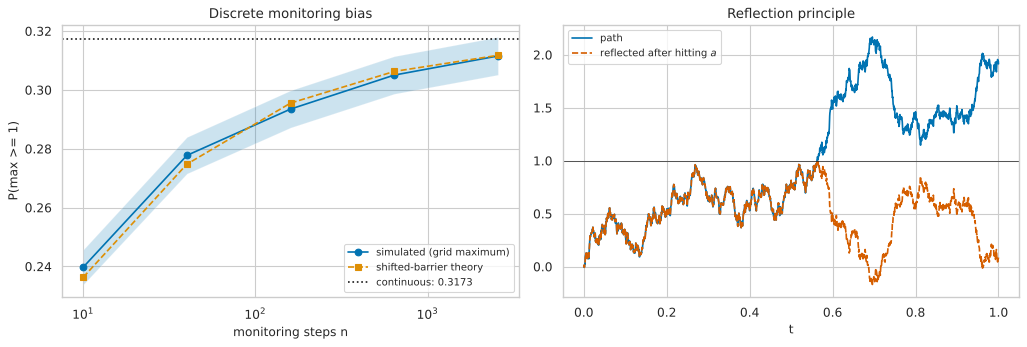

PosixPath('/home/claude/probability-simulation-laboratory/07_brownian_motion/results/exp7_5_reflection.png')

In [7]:
# F. Implementation ------------------------------------------------------------------
# bm.reflection_max_probability(a, T) = 2 * (1 - Phi(a / sqrt T))
# bm.discrete_max_exceedance(a, T, n_steps, n_paths, rng): fraction of paths whose GRID maximum reaches a
rng = make_rng(20261031 + 75)
a, T, n_paths = 1.0, 1.0, 20_000
p_cont = bm.reflection_max_probability(a, T)
rows = []
for n in [10, 40, 160, 640, 2560]:
    p_hat = bm.discrete_max_exceedance(a, T, n, n_paths, rng)
    lo, hi = wilson_interval(int(round(p_hat * n_paths)), n_paths)
    shift = 0.5826 * np.sqrt(T / n)
    rows.append(dict(n=n, P_grid_max_sim=p_hat, wilson_low=lo, wilson_high=hi, shifted_barrier_theory=bm.reflection_max_probability(a + shift, T),
                     continuous_theory=p_cont, bias=p_hat - p_cont))
tab = pd.DataFrame(rows).set_index("n")
tab.to_csv(RESULTS / "exp7_5_reflection.csv")
display(tab)

# Also a direct check of the reflection identity with a fine grid: P(max >= a) = 2 P(W_T >= a) ---------------------------
t, W = bm.brownian_paths(2000, T, 5000, rng)
print(f"fine-grid check: P(W_T >= a) = {np.mean(W[:, -1] >= a):.4f}, so 2P = {2 * np.mean(W[:, -1] >= a):.4f}  vs  P(grid max >= a) = {np.mean(W.max(axis=1) >= a):.4f}  (theory {p_cont:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].semilogx(tab.index, tab.P_grid_max_sim, "o-", label="simulated (grid maximum)")
ax[0].fill_between(tab.index, tab.wilson_low, tab.wilson_high, alpha=0.2)
ax[0].semilogx(tab.index, tab.shifted_barrier_theory, "s--", label="shifted-barrier theory"); ax[0].axhline(p_cont, color="k", ls=":", label="continuous: 0.3173")
ax[0].set(xlabel="monitoring steps n", ylabel="P(max >= 1)", title="Discrete monitoring bias"); ax[0].legend()
# a few paths, with one reflected at the first hitting time
path = W[np.argmax(W.max(axis=1) >= a)]
k_hit = int(np.argmax(path >= a)); refl = path.copy(); refl[k_hit:] = 2 * a - path[k_hit:]
ax[1].plot(t, path, label="path"); ax[1].plot(t, refl, "r--", label="reflected after hitting $a$"); ax[1].axhline(a, color="k", lw=0.6); ax[1].legend(); ax[1].set(title="Reflection principle", xlabel="t")
fig.tight_layout(); save_fig(fig, RESULTS, "exp7_5_reflection.png")

**H. Theoretical versus empirical comparison.**

See the table: the simulated grid-max probability rises with $n$ towards $0.3173$, from $0.240$ ($n=10$) to $0.312$ ($n=2560$), and the shifted-barrier formula lies inside every one of the five Wilson intervals (e.g. $0.2363$ vs $[0.234,0.246]$ at $n=10$; $0.3118$ vs $[0.305,0.318]$ at $n=2560$). The bias shrinks roughly like $\sqrt{\Delta t}$ (from $-0.078$ to $-0.006$ as $n$ goes up $256$-fold). The fine-grid check ($n=2000$, only $5{,}000$ paths) gives $2P(W_T\ge a)=0.320$ and grid maximum $0.315$ against $0.3173$, both within sampling noise ($SE\approx0.007$).

**I. Interpretation.**

Continuous and discrete monitoring are *different* problems: a barrier option monitored daily is worth materially more (knock-out) or less (knock-in) than its continuously monitored counterpart. The $\beta\sqrt{\Delta t}$ shift is the practical correction. More generally, a simulated path never "sees" the extremes between grid points, so any path-dependent estimate (maxima, barrier crossings, drawdowns) has a bias of order $\sqrt{\Delta t}$ — slower than the $\Delta t$ weak-order of terminal quantities.

**J. Limitations.**

The shifted-barrier formula is an asymptotic approximation (accurate for small $\Delta t$); with $20{,}000$ paths per row the Wilson intervals are about $\pm0.006$ wide, so differences smaller than that cannot be resolved. Only a single barrier level and horizon were explored.

**K. Research conclusion.**

The reflection principle holds, and a discrete grid under-estimates the probability by roughly the amount predicted by a $0.5826\sqrt{\Delta t}$ shift of the barrier.

**L. Further investigation.**

Use a Brownian-bridge correction between grid points (probability of crossing within an interval given its endpoints, $\exp(-2(a-x)(a-y)/\sigma^2\Delta t)$) to remove the bias; simulate a down-and-out call.

## Exercises (paper first)

1. Prove $\operatorname{Cov}(W_s,W_t)=\min(s,t)$ from independent increments. Show that $W_t^2-t$ and $\exp(\lambda W_t-\lambda^2t/2)$ are martingales.
2. Derive $\mathbb E|\Delta W|=\sqrt{2\Delta t/\pi}$ and $\operatorname{Var}(\Delta W^2)=2\Delta t^2$; deduce the mean and variance of the quadratic variation on an $n$-step grid.
3. Apply Itô's formula to $f(S)=\log S$ for $dS=\mu Sdt+\sigma SdW$ and obtain the GBM solution. Where does $-\tfrac12\sigma^2$ come from?
4. Prove the lognormal moment formulas using $\mathbb E e^{\sigma Z}=e^{\sigma^2/2}$. Compute the *mode* of $S_T$.
5. Show that $\mathbb ES^{\text{Euler}}_T=S_0(1+\mu T/n)^n$ and expand $(1+\mu T/n)^n-e^{\mu T}$ to first order in $1/n$ (weak error constant).
6. Derive the reflection principle via the strong Markov property at the hitting time $\tau_a$; deduce the density of $\tau_a$.
7. For $\mu=0.04,\ \sigma=0.3$ find the horizon $T$ beyond which more than $60\%$ of GBM paths end below $S_0$.

## Summary of Module 7
* Brownian motion is the universal scaling limit of random walks; its increments are independent, Gaussian, stationary.
* $[W]_T=T$ but total variation is infinite: the root of Itô calculus.
* GBM: lognormal, mean $S_0e^{\mu T}$, median $S_0e^{(\mu-\sigma^2/2)T}$; volatility drag $-\tfrac12\sigma^2$.
* Euler: strong order $1/2$, weak order $1$; path functionals (maxima) are biased at order $\sqrt{\Delta t}$ under discretisation.

**Next:** Module 8 — quantitative finance applications.